# JapanRead: Live Visual Speech Recognition

This notebook accompanies the desktop webcam application. It tracks the mouth in real time and records short silent video segments for visual-only inference.

**Language status**
- English: pretrained Auto-AVSR LRS3 visual checkpoint, once installed separately.
- Japanese: research/integration mode only. No Japanese checkpoint is included, so the notebook will not invent Japanese predictions.

## 1. Environment check

In [4]:
import torch
import sys

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cpu")
print("Demo device:", device)

Python: c:\Users\shash\miniconda3\python.exe
PyTorch: 2.9.1+cpu
CUDA available: False
Demo device: cpu


In [3]:
import sys, platform
print("Python:", sys.version)
print("Platform:", platform.platform())
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
except ImportError:
    print("PyTorch not installed in this notebook environment.")

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Platform: Windows-11-10.0.26300-SP0
PyTorch: 2.9.1+cpu
CUDA: False


In [5]:
from pathlib import Path

project = Path.cwd()

print("Project directory:", project)

for file in project.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".pth", ".pt", ".ckpt"]:
        print(file)

Project directory: e:\japanread\dataset\notebook


In [6]:
from pathlib import Path

project = Path.cwd().parent

print("Searching:", project)

extensions = {".pth", ".pt", ".ckpt", ".safetensors", ".bin"}

for file in project.rglob("*"):
    if file.is_file() and file.suffix.lower() in extensions:
        print(file.relative_to(project))

Searching: e:\japanread\dataset


In [7]:
from pathlib import Path

project = Path.cwd().parent

for item in sorted(project.iterdir()):
    kind = "DIR " if item.is_dir() else "FILE"
    print(f"{kind}  {item.name}")

DIR   model
DIR   notebook
DIR   raw
DIR   scripts
DIR   training


In [9]:
from pathlib import Path

project = Path.cwd().parent

for folder_name in ["model", "scripts", "training"]:
    folder = project / folder_name
    print(f"\n--- {folder_name.upper()} ---")

    for item in sorted(folder.rglob("*")):
        if item.is_file():
            print(item.relative_to(project))


--- MODEL ---

--- SCRIPTS ---
scripts\build_dataset.py
scripts\croptest.py
scripts\generate_furigana.py
scripts\testloader.py

--- TRAINING ---
training\dataset_loader.py


In [10]:
from pathlib import Path

project = Path.cwd().parent

files = [
    project / "scripts" / "croptest.py",
    project / "scripts" / "generate_furigana.py",
    project / "scripts" / "testloader.py",
    project / "training" / "dataset_loader.py"
]

for file in files:
    print(f"\n{'='*60}\nFILE: {file.name}\n{'='*60}")
    if file.exists():
        print(file.read_text(encoding="utf-8")[:7000])


FILE: croptest.py
import json
from pathlib import Path
from PIL import Image


# -------------------------
# PATHS
# -------------------------

ROOT = Path(r"E:\\japanread\\dataset\\raw\\openmantra")

JSON_PATH = ROOT / "annotation.json"

SAVE_PATH = Path(
    r"E:\japanread\dataset\raw\cropped\test.jpg"
)


# -------------------------
# LOAD JSON
# -------------------------

with open(
    JSON_PATH,
    "r",
    encoding="utf-8"
) as f:

    data = json.load(f)


# -------------------------
# GET FIRST SAMPLE
# -------------------------

book = data[0]

page = book["pages"][0]

text = page["text"][0]


# -------------------------
# LOAD IMAGE
# -------------------------

img_path = (
    ROOT /
    page["image_paths"]["ja"]
)

img = Image.open(
    img_path
)


# -------------------------
# READ COORDINATES
# -------------------------

x = text["x"]

y = text["y"]

w = text["w"]

h = text["h"]


# -------------------------
# CROP
# -------------------------

crop = img.crop(
(
    x

JAPANREAD DEMO


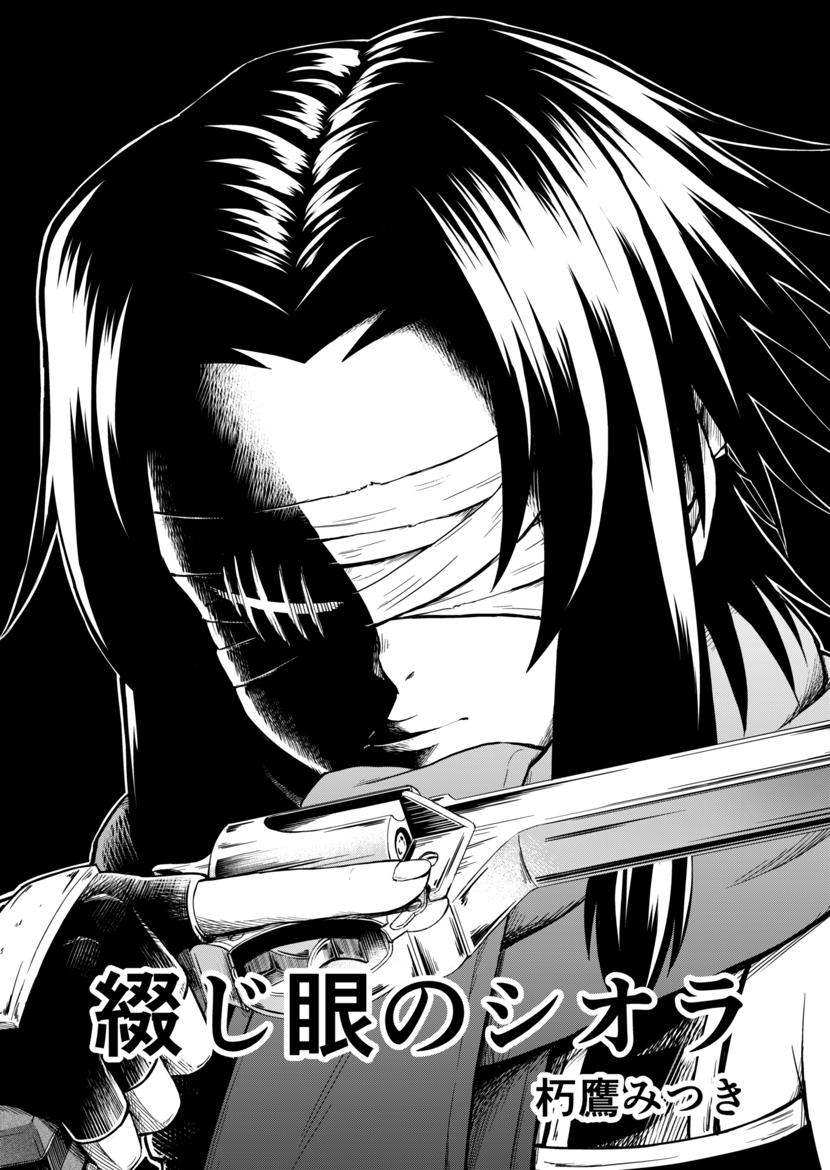


EXTRACTED TEXT:


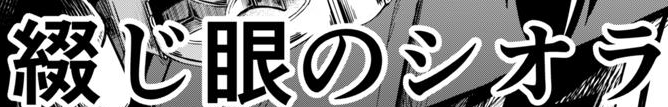


JAPANESE: 綴じ眼のシオラ
FURIGANA: とじ め の しおら
ENGLISH: bound eye siora


In [13]:
import json
from pathlib import Path
from PIL import Image
from IPython.display import display
from pykakasi import kakasi

# Project paths
project = Path.cwd().parent
root = project / "raw" / "openmantra"
json_path = root / "annotation.json"

# Load dataset
with open(json_path, "r", encoding="utf-8") as f:
    data = json.load(f)

# Get sample
book = data[0]
page = book["pages"][0]
text = page["text"][0]

# Load manga page
image_path = root / page["image_paths"]["ja"]
img = Image.open(image_path).convert("RGB")

# Crop Japanese text
x, y, w, h = [
    int(round(text[k])) for k in ("x", "y", "w", "h")
]

crop = img.crop((x, y, x + w, y + h))

# Generate furigana
kks = kakasi()
result = kks.convert(text["text_ja"])
furigana = " ".join(item["hira"] for item in result)

# Display results
print("JAPANREAD DEMO")
print("=" * 40)

display(img)
print("\nEXTRACTED TEXT:")
display(crop)

print("\nJAPANESE:", text["text_ja"])
print("FURIGANA:", furigana)
print("ENGLISH:", text["text_en"])

In [14]:
from pathlib import Path
import os

print("Notebook directory:", Path.cwd())
print("Files available:")

for p in sorted(Path.cwd().iterdir()):
    print(("DIR  " if p.is_dir() else "FILE "), p.name)

Notebook directory: e:\japanread\dataset\notebook
Files available:
FILE  dataset_pipeline.ipynb
FILE  japanread v2(encoder update).ipynb
FILE  JapanRead_Evaluation.ipynb


In [16]:
import nbformat
from pathlib import Path

file = Path.cwd() / "JapanRead_Evaluation.ipynb"
nb = nbformat.read(file, as_version=4)

for i, cell in enumerate(nb.cells):
    print(f"\n{'='*50}")
    print(f"CELL {i+1} | {cell.cell_type}")
    print(cell.source[:1500])


CELL 1 | markdown
# JapanRead: Live Visual Speech Recognition

This notebook accompanies the desktop webcam application. It tracks the mouth in real time and records short silent video segments for visual-only inference.

**Language status**
- English: pretrained Auto-AVSR LRS3 visual checkpoint, once installed separately.
- Japanese: research/integration mode only. No Japanese checkpoint is included, so the notebook will not invent Japanese predictions.

CELL 2 | markdown
## 1. Environment check

CELL 3 | code
import sys, platform
print("Python:", sys.version)
print("Platform:", platform.platform())
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
except ImportError:
    print("PyTorch not installed in this notebook environment.")

CELL 4 | mark

In [17]:
from pathlib import Path

root = Path.cwd().parent

for name in [
    "main.py",
    "requirements.txt",
    "config",
    "app",
    "models",
    "checkpoints"
]:
    p = root / name
    print(f"{name}: {'FOUND' if p.exists() else 'MISSING'}")

main.py: MISSING
requirements.txt: MISSING
config: MISSING
app: MISSING
models: MISSING
checkpoints: MISSING


## 2. Install application dependencies
Run in the project environment. Install the CUDA-enabled PyTorch build separately from https://pytorch.org/get-started/locally/.

In [8]:
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: '../requirements.txt'


## 3. Start the live webcam application
The app window uses SPACE to start/stop a recording, E to select English, J to select Japanese research mode, and Q to quit. The captured video is passed to Auto-AVSR with the video-only inference path.

In [ ]:
from pathlib import Path
import subprocess, sys
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Project root:", PROJECT_ROOT)
subprocess.run([sys.executable, str(PROJECT_ROOT / "main.py")], cwd=PROJECT_ROOT)

## 4. What are we using?

The English inference backend is the Auto-AVSR visual-only LRS3 model. 
## 5. Japanese research plan

A Japanese model requires Japanese video/transcript pairs and a Japanese decoder. Kondo & Tamura (2024) describe transfer learning from a pretrained English visual frontend with Japanese ROHAN data. This package does not contain that trained model or corpus. The Japanese option is deliberately marked unconfigured.

## 6. Evaluation talking points

- Camera frames are processed locally.
- MediaPipe FaceMesh tracks facial landmarks; lip landmarks are highlighted.
- The app records a short silent video segment.
- Auto-AVSR receives the video-only segment for English inference.
- Japanese is a planned fine-tuning track, not a completed capability.
